# 05 · Dimensionality Reduction
**Module 6 (CO5)** — Bike Sharing Demand EDA

| Syllabus topic | Section |
|---|---|
| Linear methods: Principal Component Analysis | §2 |
| Singular Value Decomposition | §3 |
| Factor Analysis | §4 |
| Intrinsic dimensionality | §5 |
| Non-linear methods: Multidimensional Scaling, Manifold Learning | §6 |
| Self-Organizing Maps | §7 |

**Data:** each of the 731 days is described by **24 numbers**, the rentals in each hour. Can these 24 dimensions be summarised by just a few?

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.manifold import MDS, Isomap, TSNE, LocallyLinearEmbedding
from sklearn.neighbors import NearestNeighbors
from minisom import MiniSom

from utils import set_style, save_fig, load_clean_daily, load_clean_hourly, PALETTE, DIV_CMAP, SEQ_CMAP

set_style()
daily = load_clean_daily()
hourly = load_clean_hourly()

profile = hourly.pivot_table(index="date", columns="hour", values="cnt", aggfunc="sum").fillna(0)
profile.index = pd.to_datetime(profile.index)
P = profile.values                     # 731 × 24
Pc = P - P.mean(axis=0)                # centred
day_type = np.where(daily["workingday"].values == 1, "Working day", "Weekend/Holiday")
print("Profile matrix:", P.shape)

Profile matrix: (731, 24)


## 1. Why reduce dimensions?
- **Visualisation** — we can only plot 2–3 dimensions.
- **Redundancy** — neighbouring hours are highly correlated (see below), so 24 columns carry much less than 24 dimensions of information.
- **Noise reduction & faster models** — fewer, cleaner features.

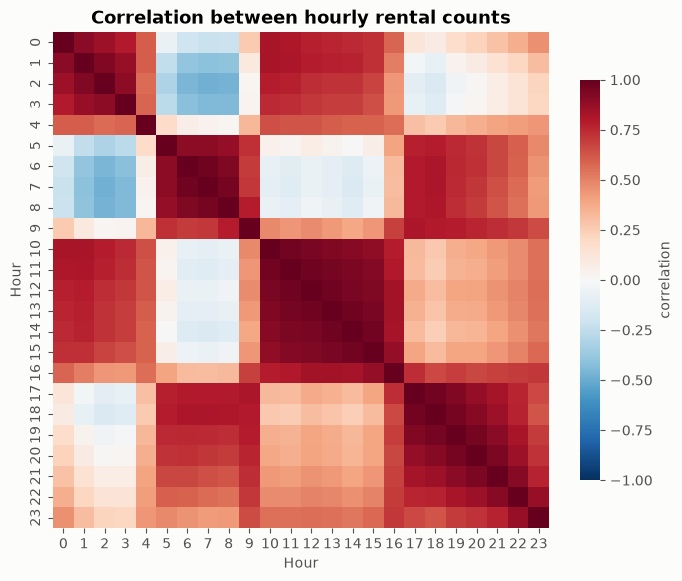

In [2]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(np.corrcoef(P.T), cmap=DIV_CMAP, vmin=-1, vmax=1, center=0, square=True, ax=ax,
            cbar_kws={"shrink": 0.8, "label": "correlation"})
ax.set_xlabel("Hour")
ax.set_ylabel("Hour")
ax.set_title("Correlation between hourly rental counts")
save_fig(fig, "05_hour_correlation")
plt.show()

## 2. Principal Component Analysis (PCA)
PCA finds new orthogonal axes (**principal components**) ordered by the variance they explain. Mathematically, they are the eigenvectors of the covariance matrix $C = \frac{1}{n-1}X_c^\top X_c$, and the eigenvalues are the explained variances.

### 2.1 PCA from scratch (eigen-decomposition)

In [3]:
C = np.cov(Pc, rowvar=False)
eigval, eigvec = np.linalg.eigh(C)
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
print("Explained variance ratio (first 5, from scratch):", (eigval / eigval.sum())[:5].round(4))

pca = PCA().fit(P)
print("Explained variance ratio (first 5, sklearn)     :", pca.explained_variance_ratio_[:5].round(4))

Explained variance ratio (first 5, from scratch): [0.618  0.3045 0.0279 0.0151 0.0074]
Explained variance ratio (first 5, sklearn)     : [0.618  0.3045 0.0279 0.0151 0.0074]


### 2.2 Scree plot and cumulative variance

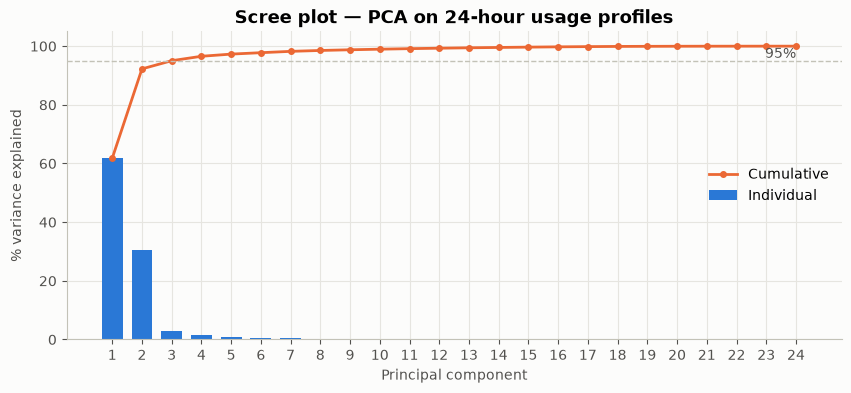

Variance explained by PC1 + PC2: 92.3 %


In [4]:
evr = pca.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, 25), evr * 100, color=PALETTE[0], width=0.7, label="Individual")
ax.plot(range(1, 25), np.cumsum(evr) * 100, color=PALETTE[1], marker="o", markersize=4, label="Cumulative")
ax.axhline(95, color="#c3c2b7", linestyle="--", linewidth=1)
ax.text(24, 96, "95%", ha="right", color="#52514e")
ax.set_xticks(range(1, 25))
ax.set_xlabel("Principal component")
ax.set_ylabel("% variance explained")
ax.set_title("Scree plot — PCA on 24-hour usage profiles")
ax.legend(loc="center right")
save_fig(fig, "05_scree")
plt.show()
print("Variance explained by PC1 + PC2:", round(evr[:2].sum() * 100, 1), "%")

### 2.3 Interpreting components (loadings) and scores

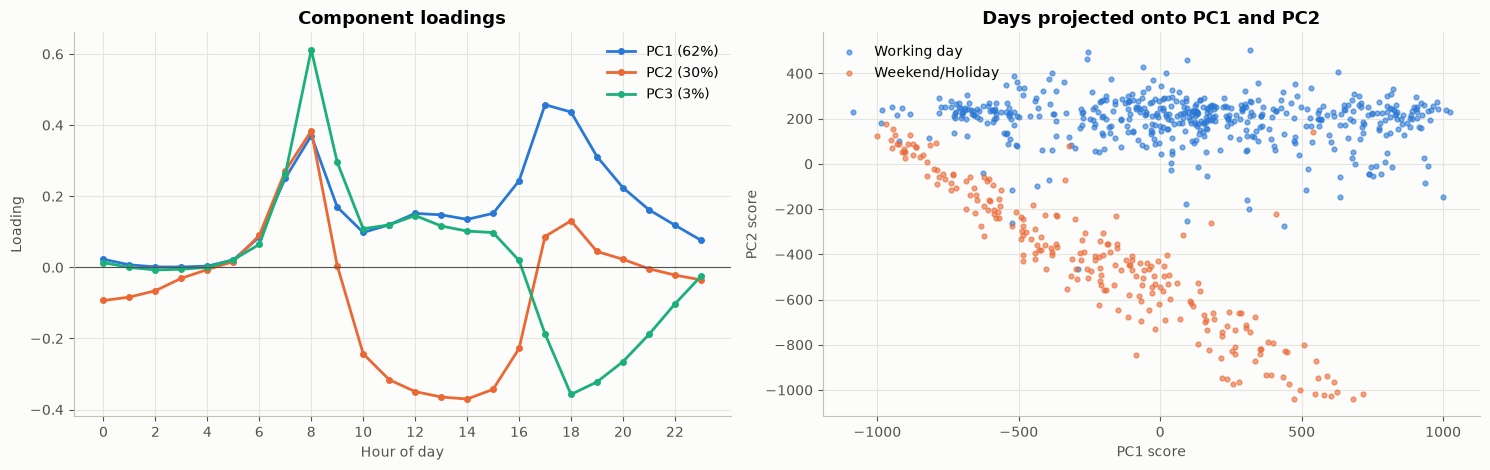

Correlation of PC1 score with daily total: 0.961


In [5]:
scores = pca.transform(P)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for i in range(3):
    axes[0].plot(range(24), pca.components_[i], marker="o", markersize=4, color=PALETTE[i],
                 label=f"PC{i + 1} ({evr[i] * 100:.0f}%)")
axes[0].axhline(0, color="#52514e", linewidth=0.8)
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Loading")
axes[0].set_title("Component loadings")
axes[0].legend()

for i, dt in enumerate(["Working day", "Weekend/Holiday"]):
    m = day_type == dt
    axes[1].scatter(scores[m, 0], scores[m, 1], s=12, alpha=0.6, color=PALETTE[i], label=dt)
axes[1].set_xlabel("PC1 score")
axes[1].set_ylabel("PC2 score")
axes[1].set_title("Days projected onto PC1 and PC2")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "05_pca_loadings_scores")
plt.show()

print("Correlation of PC1 score with daily total:", round(np.corrcoef(scores[:, 0], P.sum(axis=1))[0, 1], 3))

**Interpretation**
- **PC1** has positive loadings for every daytime hour, so it measures **overall volume**. Its score is almost perfectly correlated with the daily total.
- **PC2** is positive at the commute peaks (8 AM, 5–6 PM) and negative around midday, so it is a **commute vs leisure** axis. It separates working days from weekends almost perfectly in the scatter plot.
- Two components already explain most of the variation in a 24-dimensional dataset.

## 3. Singular Value Decomposition (SVD)
Any matrix can be factorised as $X_c = U \Sigma V^\top$.
- Columns of $V$ = principal directions (same as PCA eigenvectors)
- $\sigma_i^2 / (n-1)$ = PCA eigenvalues
- $U\Sigma$ = PCA scores

Keeping only the top *r* singular values gives the **best rank-r approximation** of the matrix (Eckart–Young theorem).

In [6]:
U, S, Vt = np.linalg.svd(Pc, full_matrices=False)
print("σ² / (n−1) (first 4):", (S[:4] ** 2 / (len(Pc) - 1)).round(1))
print("PCA eigenvalues     :", eigval[:4].round(1))
print("Directions match (|cos| of PC1 vs V1):", round(abs(Vt[0] @ eigvec[:, 0]), 6))

σ² / (n−1) (first 4): [244068.3 120253.8  11034.3   5953.1]
PCA eigenvalues     : [244068.3 120253.8  11034.3   5953.1]
Directions match (|cos| of PC1 vs V1): 1.0


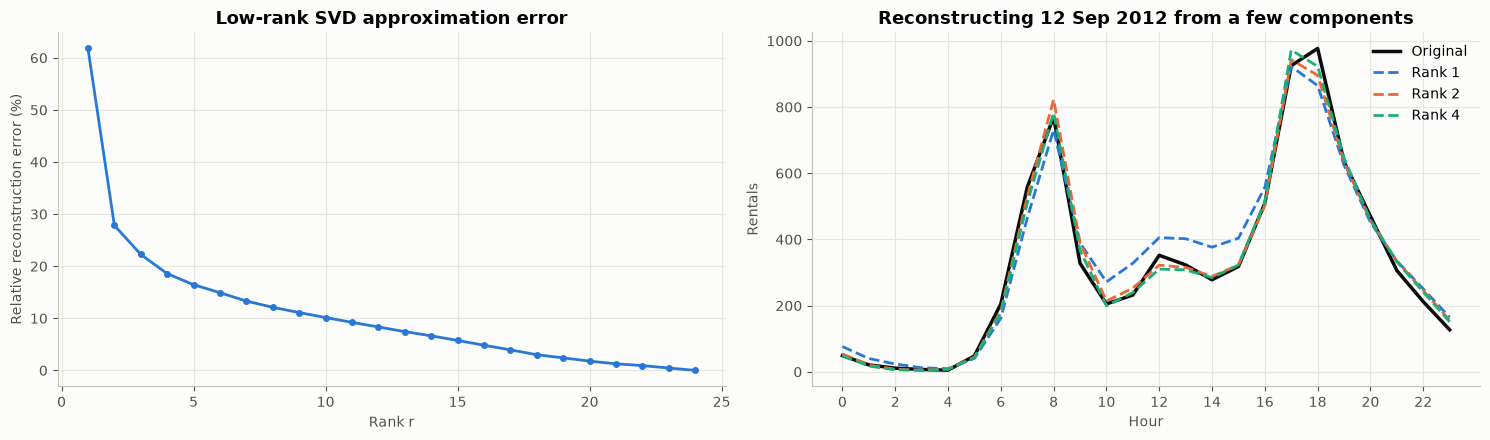

In [7]:
ranks = range(1, 25)
rel_err = [np.linalg.norm(Pc - (U[:, :r] * S[:r]) @ Vt[:r]) / np.linalg.norm(Pc) for r in ranks]

day = profile.index.get_loc(pd.Timestamp("2012-09-12"))  # a typical working day
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(list(ranks), np.array(rel_err) * 100, color=PALETTE[0], marker="o", markersize=4)
axes[0].set_xlabel("Rank r")
axes[0].set_ylabel("Relative reconstruction error (%)")
axes[0].set_title("Low-rank SVD approximation error")

axes[1].plot(range(24), P[day], color="#0b0b0b", linewidth=2.5, label="Original")
for i, r in enumerate([1, 2, 4]):
    rec = P.mean(axis=0) + (U[day, :r] * S[:r]) @ Vt[:r]
    axes[1].plot(range(24), rec, color=PALETTE[i], linestyle="--", label=f"Rank {r}")
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Rentals")
axes[1].set_title("Reconstructing 12 Sep 2012 from a few components")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "05_svd_reconstruction")
plt.show()

With only **rank 2** the reconstructed day already shows both commute peaks; rank 4 is almost identical to the original. Storing U, Σ, V for rank 4 needs ~3,000 numbers instead of 17,544 (6× compression).

## 4. Factor Analysis
**Factor Analysis (FA)** assumes the observed variables are driven by a few hidden **latent factors** plus variable-specific noise:
$$x = \Lambda f + \varepsilon$$
Unlike PCA (which explains *total* variance), FA models only the **shared** variance (*communality*). Rotation (e.g. **varimax**) makes loadings easier to interpret.

We use 7 daily variables: weather and the two user types.

In [8]:
fa_vars = ["temp", "atemp", "humidity", "windspeed", "casual", "registered"]
fa_data = daily[fa_vars].copy()
fa_data["weather_severity"] = daily["weather"].map({"Clear": 1, "Mist/Cloudy": 2, "Rain/Snow": 3})
Z = StandardScaler().fit_transform(fa_data)

# Bartlett's test of sphericity: are the variables correlated enough for FA?
R = np.corrcoef(Z, rowvar=False)
n, p = Z.shape
chi2 = -(n - 1 - (2 * p + 5) / 6) * np.log(np.linalg.det(R))
dof = p * (p - 1) / 2
print(f"Bartlett's test: χ² = {chi2:.1f}, dof = {dof:.0f}, p = {stats.chi2.sf(chi2, dof):.2e}")

# How many factors? Kaiser rule: eigenvalues of R > 1
print("Eigenvalues of correlation matrix:", np.sort(np.linalg.eigvalsh(R))[::-1].round(2))

Bartlett's test: χ² = 4009.2, dof = 21, p = 0.00e+00
Eigenvalues of correlation matrix: [2.97 1.62 0.92 0.6  0.5  0.38 0.01]


In [9]:
fa = FactorAnalysis(n_components=2, rotation="varimax", random_state=0).fit(Z)
loadings = pd.DataFrame(fa.components_.T, index=fa_data.columns, columns=["Factor 1", "Factor 2"])
# The sign of a factor is arbitrary: flip each one so its largest loading is positive
loadings *= np.sign(loadings.loc[loadings.abs().idxmax()].values.diagonal())
loadings["communality"] = (loadings ** 2).sum(axis=1)
loadings["uniqueness"] = fa.noise_variance_
loadings.round(3)

,Factor 1,Factor 2,communality,uniqueness
temp,0.993,0.034,0.987,0.013
atemp,0.997,0.048,0.996,0.004
humidity,0.098,0.914,0.845,0.156
windspeed,-0.172,-0.241,0.088,0.912
casual,0.553,-0.152,0.329,0.671
registered,0.553,-0.164,0.333,0.667
weather_severity,-0.178,0.576,0.364,0.636


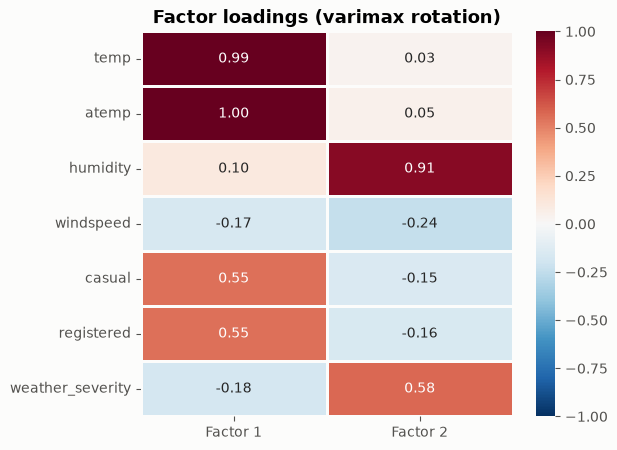

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(loadings[["Factor 1", "Factor 2"]], annot=True, fmt=".2f", cmap=DIV_CMAP, vmin=-1, vmax=1,
            center=0, linewidths=1, linecolor="#fcfcfb", ax=ax)
ax.set_title("Factor loadings (varimax rotation)")
save_fig(fig, "05_factor_loadings")
plt.show()

**Interpretation**
- **Factor 1 — "warmth / riding season":** very high loadings on temp and atemp (≈ 0.99) and moderate loadings on casual and registered riders (≈ 0.55). Warm weather lifts both user groups.
- **Factor 2 — "bad weather":** loads on humidity and weather severity (and lowers registered use).
- Windspeed has high *uniqueness*: it is not well explained by either factor.

## 5. Intrinsic dimensionality
The **intrinsic dimension** is the number of degrees of freedom actually needed to describe the data, which can be far below the number of columns. We estimate it three ways:
1. **PCA variance threshold** — components needed for 90% / 95% variance.
2. **Kaiser criterion** — eigenvalues of the *correlation* matrix greater than 1.
3. **Levina–Bickel MLE estimator** — a local, non-linear estimate based on nearest-neighbour distances:
$\hat m(x) = \Big[\frac{1}{k-1}\sum_{j=1}^{k-1} \log\frac{T_k(x)}{T_j(x)}\Big]^{-1}$

In [11]:
def mle_intrinsic_dim(X, k=10):
    dist, _ = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)
    dist = dist[:, 1:]                                   # drop self
    m = (k - 1) / np.log(dist[:, -1:] / dist[:, :-1]).sum(axis=1)
    return m.mean()

Ps = StandardScaler().fit_transform(P)
cum = np.cumsum(evr)
corr_eig = np.linalg.eigvalsh(np.corrcoef(P, rowvar=False))
idim = pd.Series({
    "PCA: components for 90% variance": int(np.searchsorted(cum, 0.90) + 1),
    "PCA: components for 95% variance": int(np.searchsorted(cum, 0.95) + 1),
    "Kaiser rule (eigenvalue > 1)": int((corr_eig > 1).sum()),
    "Levina–Bickel MLE (k = 10)": round(mle_intrinsic_dim(Ps, 10), 2),
    "Levina–Bickel MLE (k = 20)": round(mle_intrinsic_dim(Ps, 20), 2),
}, name="estimate")
idim.to_frame()

,estimate
PCA: components for 90% variance,2.00
PCA: components for 95% variance,3.00
Kaiser rule (eigenvalue > 1),2.00
Levina–Bickel MLE (k = 10),9.02
Levina–Bickel MLE (k = 20),7.41


**Reading the estimates**
- The **global, linear** estimates (PCA thresholds, Kaiser rule) say **2–3 dimensions** capture the main structure: volume plus commute-vs-leisure shape.
- The **local** Levina–Bickel estimate is higher (**≈ 7–9**). Each hourly count also carries random day-to-day noise. Noise spreads points in every direction at small scales, so a nearest-neighbour method sees extra dimensions, and fewer neighbours (smaller *k*) means a higher estimate.
- Conclusion: the *signal* is low-dimensional (2–3) even though the data are 24-dimensional; the remaining dimensions are mostly noise.

## 6. Non-linear methods
PCA can only find *linear* structure. Non-linear methods try to preserve distances or neighbourhoods on a curved **manifold**:

| Method | Preserves |
|---|---|
| **MDS** (multidimensional scaling) | pairwise distances (globally) |
| **Isomap** | geodesic distances along a k-NN graph |
| **LLE** (locally linear embedding) | each point as a linear mix of its neighbours |
| **t-SNE** | local neighbourhoods (probabilities) |

We embed the standardised 24-hour profiles into 2-D with each method.

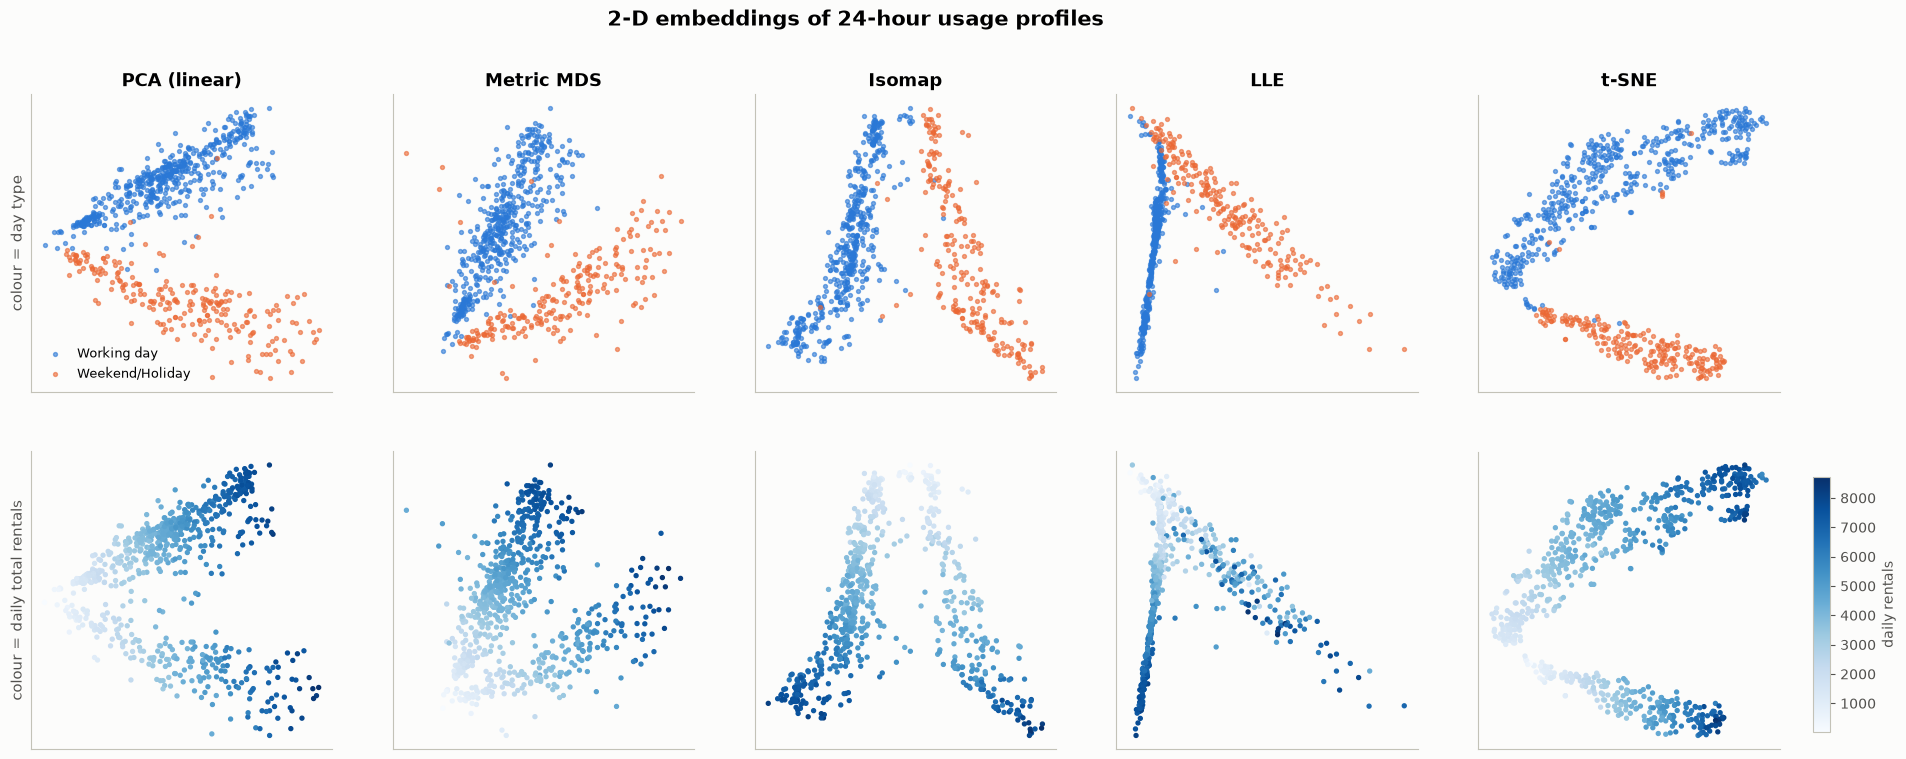

In [12]:
embeddings = {
    "PCA (linear)": PCA(2).fit_transform(Ps),
    "Metric MDS": MDS(2, random_state=0, n_init=4, init="random", normalized_stress="auto").fit_transform(Ps),
    "Isomap": Isomap(n_neighbors=15, n_components=2).fit_transform(Ps),
    "LLE": LocallyLinearEmbedding(n_neighbors=20, n_components=2, random_state=0).fit_transform(Ps),
    "t-SNE": TSNE(2, perplexity=30, random_state=0, init="pca").fit_transform(Ps),
}

fig, axes = plt.subplots(2, 5, figsize=(22, 8.5))
total = P.sum(axis=1)
for col, (name, E) in enumerate(embeddings.items()):
    for i, dt in enumerate(["Working day", "Weekend/Holiday"]):
        m = day_type == dt
        axes[0, col].scatter(E[m, 0], E[m, 1], s=8, alpha=0.6, color=PALETTE[i], label=dt)
    axes[0, col].set_title(name)
    sc = axes[1, col].scatter(E[:, 0], E[:, 1], s=8, c=total, cmap=SEQ_CMAP)
    for ax in axes[:, col]:
        ax.set_xticks([])
        ax.set_yticks([])
axes[0, 0].legend(loc="best", fontsize=9)
axes[0, 0].set_ylabel("colour = day type", fontsize=11)
axes[1, 0].set_ylabel("colour = daily total rentals", fontsize=11)
fig.subplots_adjust(right=0.92)
fig.colorbar(sc, cax=fig.add_axes([0.935, 0.13, 0.008, 0.3]), label="daily rentals")
fig.suptitle("2-D embeddings of 24-hour usage profiles", fontsize=15, fontweight="bold")
save_fig(fig, "05_manifold_embeddings")
plt.show()

In [13]:
# Quantify how well each 2-D map keeps similar days together:
# for every day, what share of its 10 nearest neighbours in 2-D have the same day type?
def neighbour_purity(E, labels, k=10):
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(E).kneighbors(E)
    return (labels[idx[:, 1:]] == labels[:, None]).mean()

pd.Series({name: neighbour_purity(E, day_type) for name, E in embeddings.items()},
          name="10-NN day-type purity").round(3).to_frame()

,10-NN day-type purity
PCA (linear),0.977
Metric MDS,0.967
Isomap,0.980
LLE,0.959
t-SNE,0.979


**Observations**
- Every method separates **working days** from **weekends** (96–98% of each day's 10 nearest neighbours share its day type), confirming this is the dominant structure.
- **PCA and MDS** give almost the same picture. For Euclidean distances, classical MDS is mathematically equivalent to PCA.
- **Isomap** and **t-SNE** unfold the data into two clean "arms", one per day type. Within each arm, days are ordered by volume (lower panel): quiet winter days at one end, busy summer days at the other.
- **LLE** squeezes working days into a thin line. It is sensitive to its neighbourhood size and can distort the global layout.
- t-SNE produces the tightest local groups but its global distances are not meaningful.

## 7. Self-Organizing Maps (SOM)
A **SOM** is a neural network with a 2-D grid of neurons. Each neuron has a weight vector (here, a 24-hour profile). Training repeatedly:
1. finds the **best-matching unit (BMU)** for a sample,
2. moves the BMU *and its grid neighbours* towards the sample.

Similar days end up on nearby neurons, giving a topology-preserving map.

In [14]:
som = MiniSom(12, 12, 24, sigma=1.8, learning_rate=0.5, random_seed=0)
som.pca_weights_init(Ps)
som.train_random(Ps, 8000)
print("Quantization error:", round(som.quantization_error(Ps), 3))
print("Topographic error :", round(som.topographic_error(Ps), 3))

Quantization error: 1.361
Topographic error : 0.066


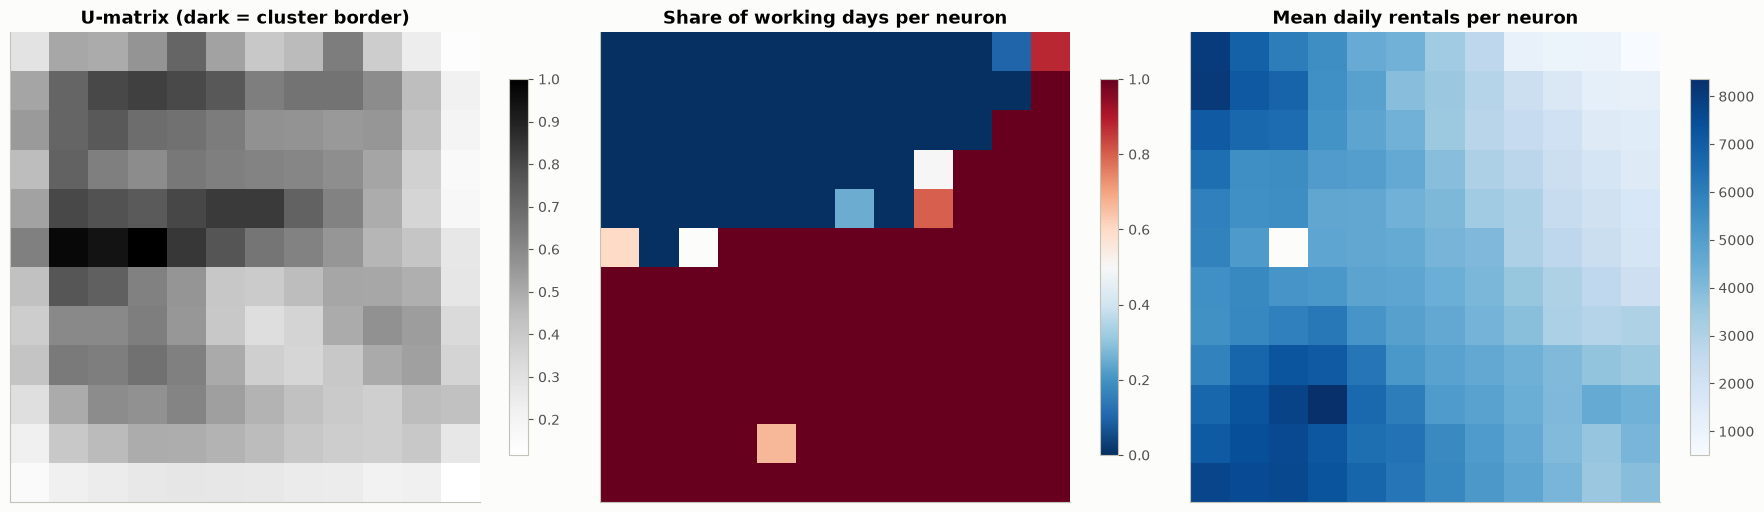

In [15]:
bmu = np.array([som.winner(x) for x in Ps])
work_share = np.full((12, 12), np.nan)
mean_total = np.full((12, 12), np.nan)
for i in range(12):
    for j in range(12):
        m = (bmu[:, 0] == i) & (bmu[:, 1] == j)
        if m.any():
            work_share[i, j] = (day_type[m] == "Working day").mean()
            mean_total[i, j] = total[m].mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
im0 = axes[0].imshow(som.distance_map().T, cmap="Greys", origin="lower")
axes[0].set_title("U-matrix (dark = cluster border)")
fig.colorbar(im0, ax=axes[0], shrink=0.8)
im1 = axes[1].imshow(work_share.T, cmap=DIV_CMAP, vmin=0, vmax=1, origin="lower")
axes[1].set_title("Share of working days per neuron")
fig.colorbar(im1, ax=axes[1], shrink=0.8)
im2 = axes[2].imshow(mean_total.T, cmap=SEQ_CMAP, origin="lower")
axes[2].set_title("Mean daily rentals per neuron")
fig.colorbar(im2, ax=axes[2], shrink=0.8)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.tight_layout()
save_fig(fig, "05_som")
plt.show()

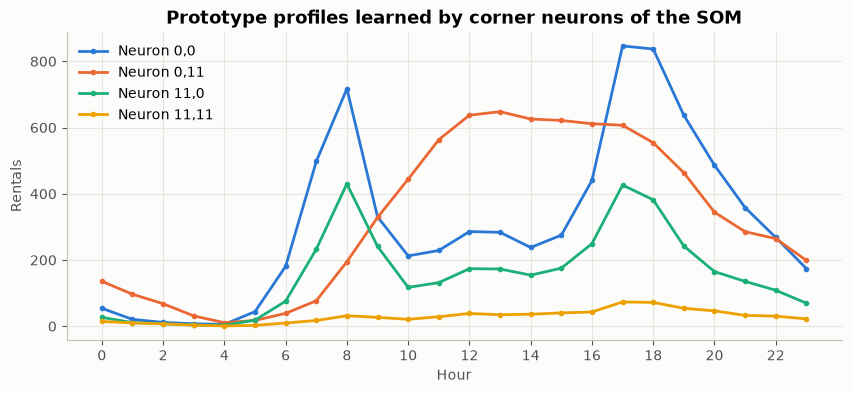

In [16]:
# Show the learned 24-h profile of a few neurons at the corners of the map
corners = [(0, 0), (0, 11), (11, 0), (11, 11)]
W = som.get_weights()
mu_, sd_ = P.mean(axis=0), P.std(axis=0)
fig, ax = plt.subplots(figsize=(10, 4))
for i, (a, b) in enumerate(corners):
    ax.plot(range(24), W[a, b] * sd_ + mu_, color=PALETTE[i], marker="o", markersize=3, label=f"Neuron {a},{b}")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour")
ax.set_ylabel("Rentals")
ax.set_title("Prototype profiles learned by corner neurons of the SOM")
ax.legend()
save_fig(fig, "05_som_prototypes")
plt.show()

The SOM arranges days on a grid: one side holds **working-day** prototypes (two peaks), the other **weekend** prototypes (one hump), and along the other direction prototypes go from **quiet winter days** to **busy summer days**. The U-matrix shows a ridge (border) between the working-day and weekend regions.

## Summary
| Method | Result |
|---|---|
| PCA | 2 components (volume + commute-vs-leisure shape) explain most of the variance in 24 hourly counts |
| SVD | Same components as PCA; a rank-4 approximation reconstructs days almost perfectly |
| Factor Analysis | Two latent factors: **warm riding season** and **bad weather** |
| Intrinsic dimension | Signal is **2–3** dimensional (PCA, Kaiser); local MLE ≈ 7–9 because of noise |
| MDS / Isomap / LLE / t-SNE | All reveal the working-day vs weekend split; Isomap and t-SNE also order days by volume |
| SOM | Topology-preserving map of day types, with a clear working/weekend border |